**Reduced feature set.** Copy of `3_methods/05_lstm.ipynb` that leaves out the five features in `EXCLUDE_COLUMNS` (see `forecast_checks.py` in this folder and `../README.md`). The helper modules are the copies in this folder, and everything is read from and written to `results/` in this folder.

# LSTM #
Recurrent network (PyTorch LSTM) on the same sliding windows as `04_cnn.ipynb`: the consumption of the 168 hours ending 145 hours before the target hour and the temperature forecast for the 168 hours up to it, read one hour per step, plus location, hour, weekday, holiday and the weather (precipitation, snowfall, wind) for the target hour. The idea is from Sadeghi Sabzevari, *Comparing 7 Machine Learning Models for Electricity Consumption Forecasting* (Medium, 2025), whose LSTM reads the last 24 hours of consumption; here the newest consumption is 145 hours old, so the window has to cover a whole week.

Everything apart from the network is the same as for the CNN: same test period as `03_xgboost.ipynb`, tuned with Optuna on three rolling validation windows at the end of the training data, so the test set is only used once at the end, and the final forecast is the mean of networks trained with different seeds.

Requires `pip install torch optuna`. The LSTM is several times slower than the CNN on a CPU; the full notebook takes a few hours.

In [1]:
import time
import numpy as np
import pandas as pd
import torch
import optuna
from forecast_checks import (LeakageChecker, ForecastValidator, MakeTrainingData, permutation_importance,
                             temperature_noise_sensitivity, save_tables)
from neural_network_helper import (SEED, MAX_EPOCHS, STATIC_COLS, WEATHER_COLS, WindowScaler, train_model, ensemble_fit,
                                   ensemble_predict, ensemble_forecast, target_day_temperature)
from lstm_helper import WindowLSTM

torch.manual_seed(SEED)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

/Users/thomasmyrseth1/Documents/NTNU/2026-2027/høst 2026/TDT4259 Applied Data Science/assignement 3 - group 11NOV/TDT4259/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#One week of hours covers both the daily and the weekly cycle
WINDOW_HOURS = 168
trainer = MakeTrainingData(window_hours=WINDOW_HOURS)
df = trainer.df

In [3]:
#Leakage check of the windows: scramble everything unknown when a day is forecast and check that its windows do not change.
#Random days, plus the week after the October DST change, where a consumption window starting 144 h back would leak.
#The weather columns are forecasts like temperature, so they are known up to and including the target day
checker = LeakageChecker(df[["location", "time", "consumption", "temperature", *WEATHER_COLS]],
                         forecast_cols=["temperature", *WEATHER_COLS])
build_windows = lambda raw: MakeTrainingData.add_sliding_window(raw, WINDOW_HOURS)
checker.check_features(build_windows)
checker.check_features(build_windows, target_days=pd.date_range("2022-10-30", "2022-11-05"))

,target_day,feature,changed_rows


In [4]:
#Same temporal split as 03_xgboost.ipynb; the row labels of the split index trainer.df
data = trainer.get_train_test()
train, test = (df.loc[data[part]["feature"].index] for part in ("train", "test"))
LeakageChecker.check_split(train["date"], test["date"])

#Optuna tunes on the same three consecutive 2-week windows at the end of the training period as 04_cnn.ipynb.
#Each window is trained on everything up to 6 days before it; several windows make the choice of model less dependent on one period
folds = [(train.loc[fit], train.loc[val]) for fit, val in MakeTrainingData.validation_windows(train["date"])]
for fit, val in folds:
    print(f"fit: {fit['date'].min().date()} - {fit['date'].max().date()}, val: {val['date'].min().date()} - {val['date'].max().date()}")

fit: 2022-04-07 - 2022-11-28, val: 2022-12-04 - 2022-12-17
fit: 2022-04-07 - 2022-12-12, val: 2022-12-18 - 2022-12-31
fit: 2022-04-07 - 2022-12-26, val: 2023-01-01 - 2023-01-14


In [5]:
feats = ["location", "hour", "weekday", *STATIC_COLS, *trainer.consumption_window, *trainer.temperature_window]
LeakageChecker.check_feature_names(feats)
LOCATIONS = sorted(df["location"].unique())

#The network cannot take missing values. Also require the point lags, so the test hours are the same as in 03_xgboost.ipynb
scored = feats + ["consumption_6days_ago", "consumption_7days_ago", "consumption_14days_ago"]
train, test = (d.dropna(subset=scored) for d in (train, test))
folds = [(fit.dropna(subset=scored), val.dropna(subset=scored)) for fit, val in folds]


def make_scaler(data):
    return WindowScaler(data, trainer.consumption_window, trainer.temperature_window, LOCATIONS)

In [6]:
#Tune on the validation windows; each window's scaler only sees its own fit period
fold_sets = []
for fit, val in folds:
    fit_scaler = make_scaler(fit)
    fold_sets.append((fit_scaler.X(fit), fit_scaler.y(fit), (fit_scaler.X(val), val["consumption"], fit_scaler, val)))
N_TRIALS = 40


def objective(trial):
    params = {"n_layers": trial.suggest_int("n_layers", 1, 2),
              "units": trial.suggest_categorical("units", [32, 64, 128]),
              "hidden": trial.suggest_categorical("hidden", [32, 64, 128]),
              "dropout": trial.suggest_float("dropout", 0.0, 0.3),
              "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
              "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
              "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024])}
    maes, epochs = [], []
    for step, (X_fit, y_fit, val_set) in enumerate(fold_sets):
        _, mae, best_epoch = train_model(params, X_fit, y_fit, MAX_EPOCHS, val=val_set, model_class=WindowLSTM)
        maes.append(mae)
        epochs.append(best_epoch)
        #Every trial sees the windows in the same order, so the running mean can be compared between trials
        trial.report(np.mean(maes), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("best_epoch", round(np.mean(epochs)))
    trial.set_user_attr("fold_maes", maes)
    return np.mean(maes)


#shortcut: the Optuna search (~10 h) was not rerun after the feature ablation removed snowfall and wind; the else branch
#holds its best parameters and epoch, found with every weather feature. Set TUNE = True to search again with the current features
TUNE = False
start = time.time()
if TUNE:
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=0))
    #Fixed number of trials, not a time budget: with a timeout the number of trials (and so the chosen model) depends on machine speed
    study.optimize(objective, n_trials=N_TRIALS)
    pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
    print(f"{len(study.trials)} trials ({pruned} pruned) in {time.time() - start:.0f} s")
    print("Best mean validation MAE:", study.best_value, "per window:", study.best_trial.user_attrs["fold_maes"],
          "at epoch", study.best_trial.user_attrs["best_epoch"])
    best_params, best_epoch = study.best_params, study.best_trial.user_attrs["best_epoch"]
else:
    best_params = {"n_layers": 1, "units": 128, "hidden": 128, "dropout": 0.29804364170870246,
                   "lr": 0.0009073979900917517, "weight_decay": 5.7013497674065925e-06, "batch_size": 256}
    best_epoch = 19
best_params

{'n_layers': 1,
 'units': 128,
 'hidden': 128,
 'dropout': 0.29804364170870246,
 'lr': 0.0009073979900917517,
 'weight_decay': 5.7013497674065925e-06,
 'batch_size': 256}

In [7]:
#Check the chosen model on every validation window before touching the test set: per location, so a location where it
#loses to the baseline shows up here. The windows contain Christmas and New Year, which the test period does not,
#so their forecasts are saved for the holiday analysis in 07_error_analysis.ipynb
val_pred = [ensemble_forecast(best_params, best_epoch, fit, val, make_scaler(fit),
                              model_class=WindowLSTM)
            for fit, val in folds]
val_all = pd.concat([val for _, val in folds])
val_validator = (ForecastValidator(val_all["consumption"], groups=val_all["location"])
                 .add("Same hour last week", val_all["consumption_7days_ago"], baseline=True)
                 .add("LSTM", np.concatenate(val_pred)))
val_validator.save_predictions("results/lstm_validation_predictions.json")
val_validator.per_group(skill=True)

mae      rmse       nmae      bias  \
model               group                                                  
Same hour last week bergen       0.494656  0.571749  14.471781 -0.068834   
                    helsingfors  0.135916  0.178670   2.059390  0.007267   
                    oslo         2.342415  2.610506  17.462961 -0.188957   
                    stavanger    0.915348  1.048347  14.607397 -0.083916   
                    tromsø       0.187643  0.226556   9.280477 -0.027062   
                    trondheim    0.563126  0.654318  15.066702 -0.076558   
LSTM                bergen       0.225964  0.291384   6.610854 -0.138926   
                    helsingfors  0.154022  0.198659   2.333739  0.024117   
                    oslo         1.119316  1.324258   8.344626 -0.406647   
                    stavanger    0.464621  0.611011   7.414560 -0.370048   
                    tromsø       0.105431  0.130019   5.214423 -0.021148   
                    trondheim    0.311071  0.388008   8.322852 -0.059490   

                                    skill  
model               group                  
Same hour last week bergen       0.000000  
                    helsingfors  0.000000  
                    oslo         0.000000  
                    stavanger    0.000000  
                    tromsø       0.000000  
                    trondheim    0.000000  
LSTM                bergen       0.543190  
                    helsingfors -0.133218  
                    oslo         0.522153  
                    stavanger    0.492411  
                    tromsø       0.438130  
                    trondheim    0.447600

In [8]:
#Refit on the whole training period with the best parameters and number of epochs, then predict the test period once.
#The networks are kept, so the robustness checks below can predict without retraining
scaler = make_scaler(train)
models = ensemble_fit(best_params, best_epoch, train, scaler, model_class=WindowLSTM)
predict_mw = lambda data: ensemble_predict(models, data, scaler)
pred = predict_mw(test)
print(f"Total training time: {time.time() - start:.0f} s")
test = test.assign(pred=pred)

Total training time: 10231 s


In [9]:
#Same hours as the comparison in 03_xgboost.ipynb (test rows where every lag exists), so the tables can be compared directly
validator = (ForecastValidator(test["consumption"], groups=test["location"])
             .add("Same hour last week", test["consumption_7days_ago"], baseline=True)
             .add("LSTM", test["pred"]))
validator.summary()

,mae,rmse,nmae,bias
Same hour last week,0.494720,0.806999,8.983281,0.033943
LSTM,0.286146,0.418565,5.195926,-0.046909


In [10]:
validator.save_to_json("results/lstm.json")
validator.save_predictions("results/lstm_predictions.json")

In [11]:
#Robustness on the test period, used by 07_error_analysis.ipynb. Importance: how much the MAE grows when a group of inputs
#is shuffled (same groups as 04_cnn.ipynb). The test period has no holidays, so holiday is part of calendar.
#Temperature noise: the error of a real day-ahead forecast, added to the part of the temperature window in the target day
FEATURE_GROUPS = {"consumption": trainer.consumption_window, "temperature": trainer.temperature_window,
                  "calendar": ["hour", "weekday", "holiday"], "other weather": WEATHER_COLS}
importance = permutation_importance(predict_mw, test, test["consumption"], FEATURE_GROUPS)
temperature_noise = temperature_noise_sensitivity(predict_mw, test, test["consumption"], test["date"],
                                                  trainer.temperature_window,
                                                  in_target_day=target_day_temperature(test, trainer.temperature_window))
save_tables("results/lstm_robustness.json", importance=importance, temperature_noise=temperature_noise)
importance

,mae_increase,mae_increase_std,relative_increase
feature_group,,,
consumption,0.064492,0.000646,22.537975
temperature,0.238560,0.003913,83.370011
calendar,0.136454,0.002925,47.686680
other weather,0.003109,0.000154,1.086346


In [12]:
temperature_noise

,mae,mae_std,relative_increase
sigma,,,
0.0,0.286146,0.000000,0.000000
0.5,0.289426,0.000730,1.146111
1.0,0.296585,0.001721,3.648121
2.0,0.315953,0.002221,10.416684
3.0,0.352596,0.002478,23.222562


In [13]:
validator.per_group()

mae      rmse       nmae      bias
model               group                                               
Same hour last week bergen       0.346885  0.419259  10.768142  0.052396
                    helsingfors  0.136010  0.261839   2.120825  0.006952
                    oslo         1.303123  1.679950  10.670598  0.067276
                    stavanger    0.594432  0.743627  10.514005  0.053905
                    tromsø       0.181393  0.226528   9.410661  0.002203
                    trondheim    0.406683  0.486778  11.252339  0.020940
LSTM                bergen       0.236694  0.287941   7.347560 -0.156589
                    helsingfors  0.137210  0.214472   2.139531  0.040142
                    oslo         0.624277  0.785000   5.111880  0.101365
                    stavanger    0.373253  0.452446   6.601907 -0.061176
                    tromsø       0.093268  0.117886   4.838720 -0.031550
                    trondheim    0.252259  0.295829   6.979649 -0.173698

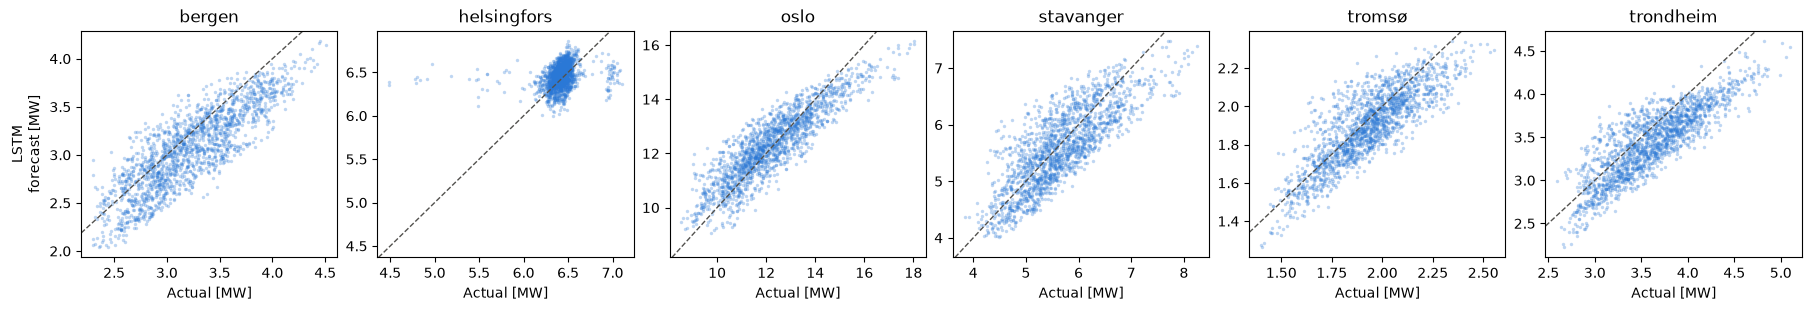

In [14]:
validator.plot_predicted_vs_actual_consumption(no_baseline=True)

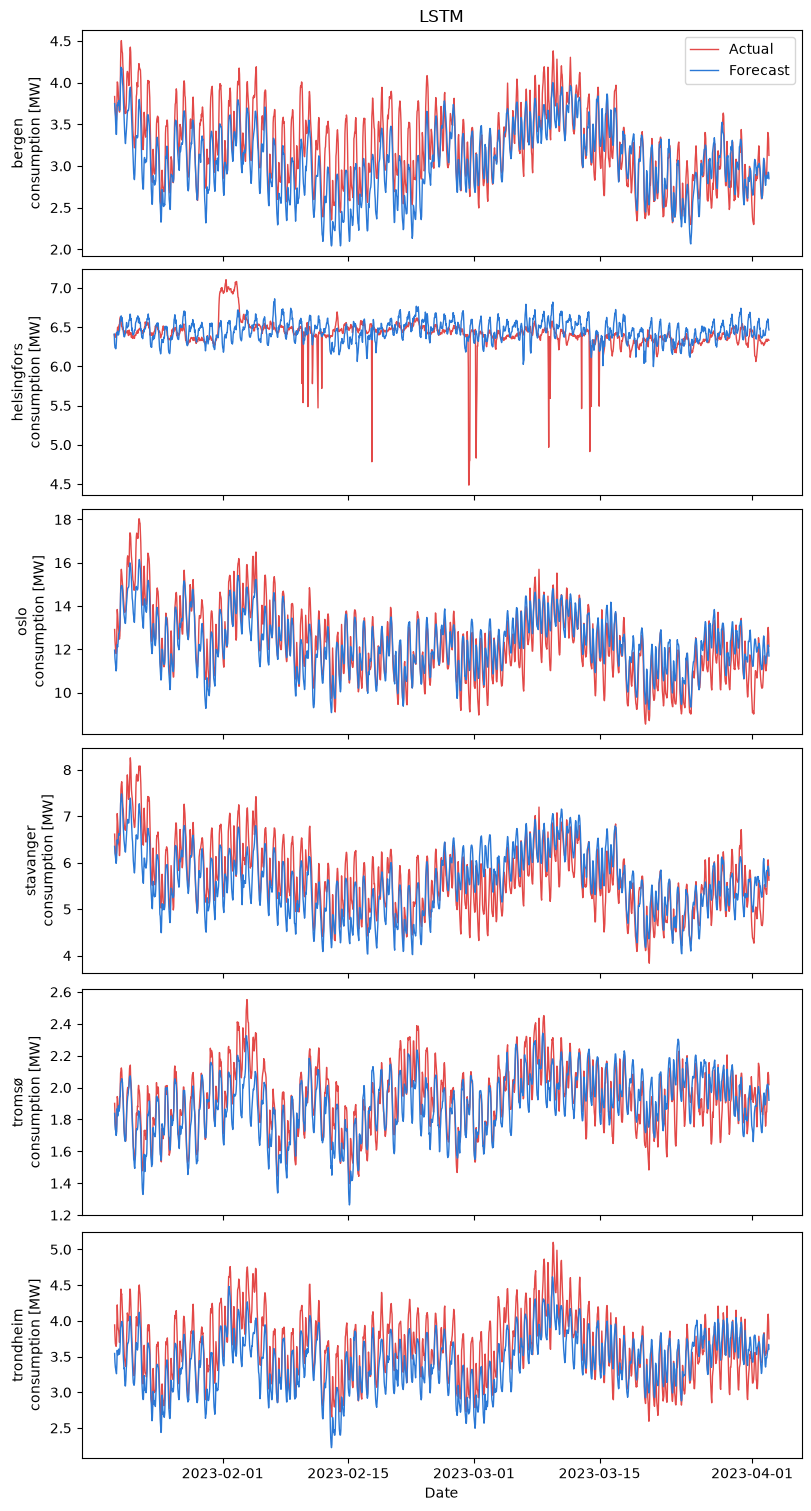

In [15]:
validator.plot_consumption_over_time(test["time"], no_baseline=True)